# mESC auxin depletions (WT, RAD21, YY1, WAPL, CTCF): jet length, angle deviation, and aggregate contact maps

In [1]:
import sys
sys.path.append('..')
from utils.plotting import plot_n_hic, genomic_labels, genomic_labels2
from notebooks.func_plotting import add_pairwise_sig, title_boxplot
from notebooks.func_iou import match_by_iou, unique_pairs
from notebooks.func_pileup import get_pileups, remove_stacks, generate_bed_3

import os
import yaml
import numpy as np
import pandas as pd
import bioframe as bf
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, FixedLocator

In [2]:
cf = """
samples:

  GSE130275_mESC_WT_combined_2.6B_2nkb:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/GSE130275_mESC_WT_combined_2.6B.hic"
    genome: "mm10"
    norm: "KR"
    res: "25000"
    q_val: "0.5"
    q_val_white: "0.1"

  mESC_RAD21-auxin-3hr_microc_Hsieh-2022_GSE178982_mm10_2nkb:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/mESC_RAD21-auxin-3hr_microc_Hsieh-2022_GSE178982_mm10.hic"
    genome: "mm10"
    norm: "NONE" # KR failed, VC_SQRT failed, VC failed
    res: "20000" # 25 kb not present
    q_val: "0.5"
    q_val_white: "0.1"

  mESC_YY1-auxin-3hr_microc_Hsieh-2022_GSE178982_mm10_2nkb:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/mESC_YY1-auxin-3hr_microc_Hsieh-2022_GSE178982_mm10.hic"
    genome: "mm10"
    norm: "VC_SQRT"
    res: "20000" # 25 kb not present
    q_val: "0.5"
    q_val_white: "0.1"

  mESC_WAPL-auxin-3hr_microc_Hsieh-2022_GSE178982_mm10_2nkb:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/mESC_WAPL-auxin-3hr_microc_Hsieh-2022_GSE178982_mm10.hic"
    genome: "mm10"
    norm: "VC_SQRT"
    res: "20000" # 25 kb not present
    q_val: "0.5"
    q_val_white: "0.1"

  mESC_CTCF-auxin-3hr_microc_Hsieh-2022_GSE178982_mm10_2nkb:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/mESC_CTCF-auxin-3hr_microc_Hsieh-2022_GSE178982_mm10.hic"
    genome: "mm10"
    norm: "VC_SQRT"
    res: "20000" # 25 kb not present
    q_val: "0.5"
    q_val_white: "0.1"
"""

samples = yaml.safe_load(cf)["samples"]
names = list(samples.keys())

In [3]:
output_name = "v2.0.3"
data_name = "mESC all pairs"
save_path = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/analysis_{output_name}"

names_abrev = ["WT", "RAD21", "YY1", "WAPL", "CTCF"]
names_abrev_dict = dict(zip(names, names_abrev))

genome = "mm10"
chrom_sizes = bf.fetch_chromsizes(genome, as_bed=True)
common_chroms = chrom_sizes["chrom"].tolist()
common_chroms.remove('chrY')

In [4]:
# Load MIA-Jet summary and expanded tables
table_dict = {}
position_dict = {}
hic_files = []
normalizations = []
resolutions = []
for name in names:
    attributes = samples[name]
    hic_file = attributes["file"]
    hic_name = os.path.basename(hic_file).split(".hic")[0]
    resolution = int(attributes["res"])
    q_val_white_str = f"q_val_{attributes['q_val']}-{attributes['q_val_white']}"

    folder = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{hic_name}_chr_combined_{genomic_labels(resolution)}"
    prefix = f"{hic_name}_chr_combined_"
    suffix = f"_{genomic_labels(resolution)}_summary_table.csv"
    fname = next(f for f in os.listdir(folder) if f.startswith(prefix) and f.endswith(suffix) and q_val_white_str in f)
    result_type = fname[len(prefix):-len(suffix)]
    f_e = os.path.join(folder, f"{hic_name}_chr_combined_{result_type}_{genomic_labels(resolution)}_expanded_table.csv")

    s = pd.read_csv(os.path.join(folder, fname), comment="#")
    e = pd.read_csv(f_e, comment="#")
    s['length'] *= resolution  # bins -> bp

    # Per-jet mean absolute deviation of the ridge angle from 90 degrees
    e['angle_deviation'] = np.abs(e['angle'].values - 90)
    s['angle_dev_mean'] = s['unique_id'].map(e.groupby('unique_id')['angle_deviation'].mean())

    table_dict[name] = s
    position_dict[name] = e
    hic_files.append(hic_file)
    normalizations.append(attributes["norm"])
    resolutions.append(resolution)

## Violin plot of jet length

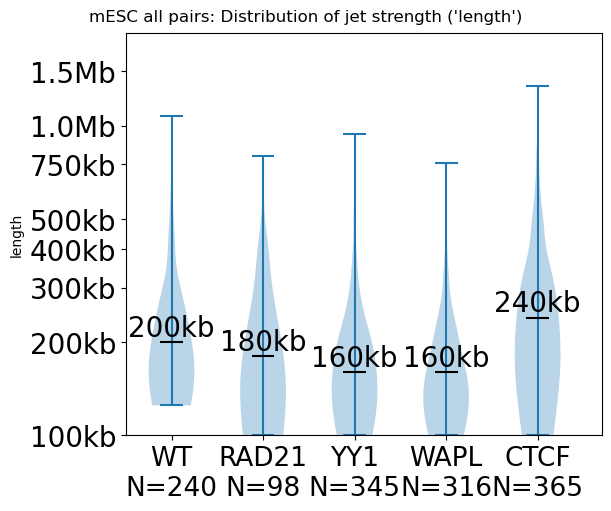

In [5]:
# PLOT JET STRENGTH VIOLIN PLOT OF ALL CALLED
strength_col = "length"  # MIA-Jet "jet strength"

fig, ax = plt.subplots(figsize=(6, 5), layout='constrained')

data = [s[strength_col].values for s in table_dict.values()]
positions = np.arange(1, len(data) + 1)

parts = ax.violinplot(data, positions=positions,
                      showmeans=False, showmedians=True, showextrema=True)
for pc in parts['bodies']:
    pc.set_alpha(0.3)

parts['cmedians'].set_color('black')
parts['cmedians'].set_label('median')

# annotate median directly on the figure, at its line
for pos, d in zip(positions, data):
    med = np.median(d)
    ax.text(pos, med, f"{genomic_labels2(med)}",
            color='black', ha='center', va='bottom', fontsize=20,
            clip_on=False)

# tick labels carry the group name + N
labels = [
    f"{names_abrev_dict[name]}\nN={len(d)}"
    for name, d in zip(table_dict.keys(), data)
]
ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_ylabel(strength_col)
ax.tick_params(axis='y', labelsize=20)
ax.tick_params(axis='x', labelsize=19, rotation=0)

ax.set_yscale('log')

# Manual tick positions (bp)
ticks = [
    100e3, 200e3, 300e3, 400e3, 500e3,
    750e3, 1.0e6, 1.5e6,
]
ax.yaxis.set_major_locator(FixedLocator(ticks))
ax.yaxis.set_minor_locator(FixedLocator([]))  # no minor ticks
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: genomic_labels2(x)))

# give the right-hand text labels a little room
ax.set_xlim(0.5, len(data) + 0.7)
ax.set_ylim(100e3, 2e6)

fig.suptitle(f"{data_name}: Distribution of jet strength ('{strength_col}')")

plt.savefig(f"{save_path}/{data_name}_{result_type}_summary_violin_{strength_col}.png", dpi=300)
plt.show()

## Angle deviation: WT & CTCF common jets, and all WAPL jets

In [6]:
# Match WT and CTCF jets by IoU (per chromosome) to find the jets common to both
buffer_radius = 3 * resolution  # 3 bins (resolution of the last sample loaded)
iou_threshold = 0  # ANY overlap

n1, n2 = names[0], names[4]  # WT, CTCF
common_pairs = []  # (WT unique_id, CTCF unique_id)
for chrom in common_chroms:
    t1 = position_dict[n1].loc[position_dict[n1]["chrom"] == chrom]
    t2 = position_dict[n2].loc[position_dict[n2]["chrom"] == chrom]

    # Compute the pairs of jets in each direction, then keep unique pairs
    pairs12 = match_by_iou(t1, t2, buffer_radius=buffer_radius, iou_threshold=iou_threshold, x_label="x (bp)", y_label="y (bp)")
    pairs21 = match_by_iou(t2, t1, buffer_radius=buffer_radius, iou_threshold=iou_threshold, x_label="x (bp)", y_label="y (bp)")
    common_pairs += unique_pairs(pairs12, pairs21, method="optimal")

# Boxplot groups: WT & CTCF common jets, plus all WAPL jets
group_names = [n1, n2, names[3]]  # WT, CTCF, WAPL
print(f"{len(common_pairs)} jets common to {names_abrev_dict[n1]} and {names_abrev_dict[n2]}")

76 jets common to WT and CTCF


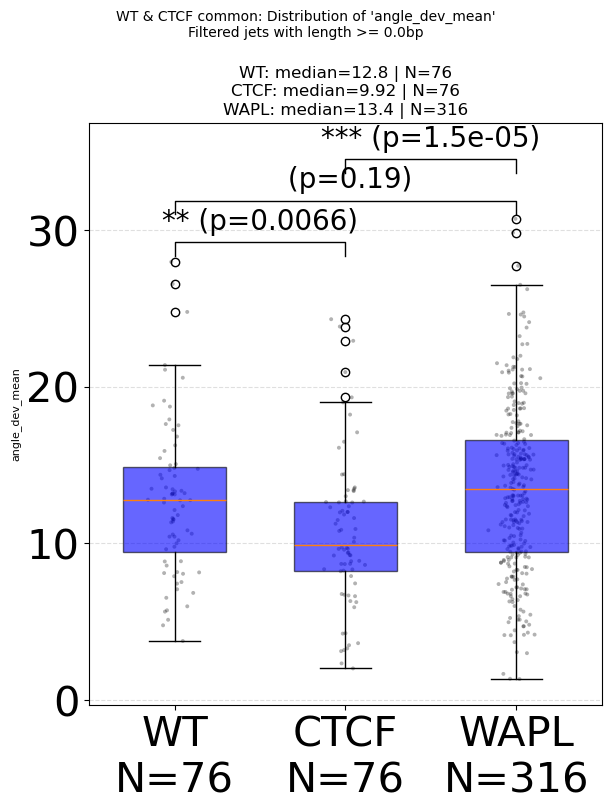

In [7]:
length_thresh = 0

tables_pair_dict = {}
for i, n in enumerate(group_names):
    s = table_dict[n]
    if i <= 1:
        # WT, CTCF: keep only the common jets
        uid_list = [uid[i] for uid in common_pairs]
        s = s.loc[s['unique_id'].isin(uid_list)]
    # WAPL: keep all jets

    # filter length threshold
    tables_pair_dict[n] = s.loc[s['length'] >= length_thresh].reset_index(drop=True)


# PLOT ANGLE DEVIATION BOXPLOT
strength_col = "angle_dev_mean"

fig, ax = plt.subplots(1, 1, figsize=(6, 8), layout="constrained")

# one array per group, NaNs dropped
data = []
for s in tables_pair_dict.values():
    vals = np.asarray(s[strength_col].values)
    data.append(vals[~np.isnan(vals)])

positions_x = np.arange(1, len(data) + 1)

add_pairwise_sig(ax, positions_x, data, fontsize=20, pad_from_max=-5, y_pad=0.09,
                 pairs_to_compare=None)

bp = ax.boxplot(data, patch_artist=True, widths=0.6)
for i in range(len(data)):
    bp['boxes'][i].set_facecolor('blue')
    bp['boxes'][i].set_alpha(0.6)
for pos, vals in zip(positions_x, data):
    x = np.full_like(vals, pos, dtype=float) + np.random.normal(0, 0.05, len(vals))
    ax.scatter(x, vals, s=8, alpha=0.3, color='k', edgecolor='none')

# tick labels carry the group name + N; clean names go to title_boxplot
labels = [
    f"{names_abrev_dict[name]}\nN={len(d)}"
    for name, d in zip(tables_pair_dict.keys(), data)
]
box_names = [names_abrev_dict[name] for name in tables_pair_dict.keys()]

ax.set_xticks(positions_x)
ax.set_xticklabels(labels, rotation=0, ha="center")
ax.set_title(title_boxplot("", box_names, data))
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_ylabel(strength_col, fontsize=8)

ax.tick_params(axis='y', labelsize=30)
ax.tick_params(axis='x', labelsize=30)

ax.set_ylim(top=np.max([np.max(d) for d in data]) * 1.2)

fig.suptitle(f"{names_abrev_dict[group_names[0]]} & {names_abrev_dict[group_names[1]]} common: Distribution of '{strength_col}'\nFiltered jets with length >= {genomic_labels(length_thresh, N=1)}",
             fontsize=10)

plt.savefig(f"{save_path}/{names_abrev_dict[group_names[0]]}_{names_abrev_dict[group_names[1]]}_{result_type}_summary_boxplot_{strength_col}_{length_thresh}.png", dpi=300)
plt.show()

## Aggregate contact maps: reference location is WT

In [8]:
fixed_window_size = 3e6

# Pileup parameters
data_type = "oe"

# Reference jet locations, used for every sample
name_idx = 0  # WT
common_bed_df = generate_bed_3(table_dict[names[name_idx]], position_dict[names[name_idx]],
                               project_midpoint_to_diag=True, eps=fixed_window_size // 2)

In [9]:
agg_map = []
vmaxes = []
vmins = []
df_stack = []

for idx in range(len(names)):
    # Get pileups at the reference locations
    s, d = get_pileups(
        hic_file=hic_files[idx],
        bed_df_in=common_bed_df,
        resolution=resolutions[idx],
        chrom_sizes=chrom_sizes,
        chromosomes='all',
        window_range=(None, None),
        data_type=data_type,
        normalization=normalizations[idx],
        sort=False,
    )

    # Remove centromeres and resize square stacks
    s, d = remove_stacks(s, d, resolution=resolutions[idx], fixed_window_size=fixed_window_size)

    if data_type == "observed":
        s = np.log10(s + 1) # log transform for visualization

    a = np.nanmean(s, axis=0)  # average over all stacks

    vmaxes.append(np.nanpercentile(a, 98))  # 98th percentile for color scaling
    vmins.append(np.nanpercentile(a, 1))  # 1st percentile for color scaling
    agg_map.append(a)
    df_stack.append(d)  # kept for N in the titles

  0%|          | 0/240 [00:00<?, ?it/s]

  1%|▏         | 3/240 [00:00<00:10, 23.30it/s]

  2%|▎         | 6/240 [00:00<00:11, 20.88it/s]

  4%|▍         | 9/240 [00:00<00:11, 19.92it/s]

  5%|▌         | 13/240 [00:00<00:10, 22.11it/s]

  7%|▋         | 17/240 [00:00<00:08, 25.64it/s]

... (304 outputs left out)

 94%|█████████▍| 226/240 [00:07<00:00, 30.16it/s]

 96%|█████████▋| 231/240 [00:07<00:00, 33.57it/s]

 98%|█████████▊| 235/240 [00:07<00:00, 33.81it/s]

100%|██████████| 240/240 [00:07<00:00, 32.72it/s]

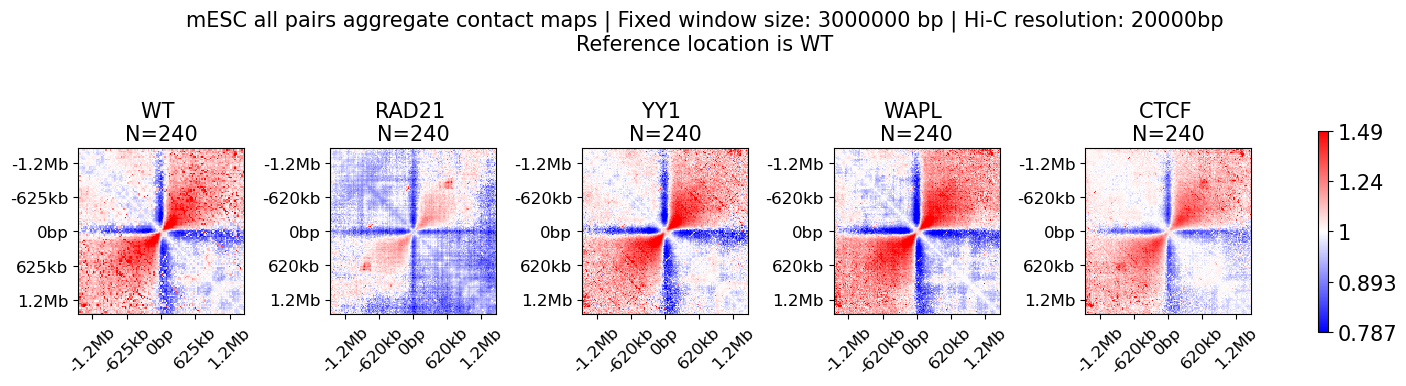

In [10]:
titles = [f"{names_abrev_dict[names[i]]} \nN={len(df_stack[i])}" for i in range(len(names))]

plot_n_hic(
    agg_map,
    suptitle=f"{data_name} aggregate contact maps | Fixed window size: {int(fixed_window_size)} bp | Hi-C resolution: {resolution}bp\nReference location is {names_abrev_dict[names[name_idx]]}",
    resolution=resolutions,
    cmap_label=None,
    titles=titles,
    cmap='bwr',
    vcenter=1,
    standardize_cbar=True,
    show=True,
    vmax=vmaxes,
    vmin=vmins,
    share_xy=False,
    ppr=5,
    figsize=(4 * 3.5, 4),
    savepath=f"{save_path}/{data_name}_reference{names_abrev_dict[names[name_idx]]}_agg_map-{data_type}_fixed_ws-{fixed_window_size}.png",
    cbar_fontsize=15,
    fig_fontsize=15,
    tick_fontsize=12,
    hide_axis=False,
    center_window=True,
)